# Feature space: concepts, timing and redundancy

**Question:** Which engineered fields represent different baseball information, and which repeat the same quantities?

This additive stage preserves the database and previous PCA/PLS work. It inventories the 536 registered predictors plus two existing cohort context fields. All screening and correlations use **2015–2021 training data**; validation is 2022–2023. The already examined 2024–2025 period is exploratory transfer, not independent confirmation.

The inherited **Elbow / UCL** endpoint is broad initial elbow anatomy. Confirmed UCL-only event support is much smaller and is reported below. Current-outing values are known after the appearance; prior histories exclude the current date. The executable, resumable companion is `python -m src.injury_analysis.consolidation_workflow`. These notebooks inspect its verified artifacts without refitting completed stages.

In [1]:
from pathlib import Path
import sys
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'config/feature_consolidation.yaml').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
import json
import pandas as pd
from IPython.display import display,Markdown,Image
from src.injury_analysis.consolidation_common import OUT,CACHE,read_table
assert (OUT/'candidate_freeze.json').exists(), 'First run: .venv/bin/python -m src.injury_analysis.consolidation_workflow'
def plot(name):display(Image(filename=str(OUT/'figures'/f'{name}.png')))
display(read_table('cohort_counts'))
display(read_table('event_support'))

,partition,rows,positive_rows,pitchers,prevalence
0,test,27665,708,789,0.025592
1,train,81145,1441,1290,0.017758
2,validation,26796,600,783,0.022391


,partition,rows,positive_rows,represented_events,initial_explicit_ucl_events,later_supplemental_ucl_confirmation,first_appearance,last_appearance
0,test,27665,708,110,5,24,2024-03-20,2025-09-24
1,train,81145,1441,223,15,46,2015-04-14,2021-09-24
2,validation,26796,600,89,3,17,2022-04-07,2023-09-29


## Schema-backed inventory and deterministic relationships

Actual DuckDB schema, source builders and dictionary define classification. Builder suffix precedence corrects generic dictionary prose for slopes and three-outing changes. Source and timing clarifications are in a separate reconciled inventory; the original numerical inventory remains unchanged.

Do not equate 538 registered/context fields with 538 usable measurements. Training-only exclusions concern missingness above 60%, fewer than 100 measured pitchers, constant fields, circular spin-axis coordinates requiring proper encoding, and unverified publication timing for prior surgery fields. Coverage predictors remain in separate sensitivity analyses. These choices define the long-history analysis, not universal exclusions for future richer-era work.

In [2]:
inventory=read_table('feature_inventory_review')
display(read_table('feature_group_inventory'))
display(inventory[['feature','feature_group','underlying_concept','representation','source_variables',
 'timing_availability','current_appearance_included','training_missing_fraction','screen_exclusion']])
display(read_table('feature_definition_updates'))
display(read_table('deterministic_dependencies'))

,feature_group,features,eligible,near_constant
0,Velocity,60,37,0
1,Release position and variability,116,70,0
2,Extension,50,27,0
3,Arm angle,20,0,0
4,Spin,59,26,0
5,Pitch movement,41,21,0
6,Location and strike fractions,46,34,0
7,Pitch mix and pitch-type counts,66,66,0
8,Workload and rest,29,29,0
9,Role and recent starts,5,5,0


,feature,feature_group,underlying_concept,representation,source_variables,timing_availability,current_appearance_included,training_missing_fraction,screen_exclusion
0,total_pitches,Workload and rest,total_pitches,count,physical Statcast pitch rows,after completed outing,True,0.000000,NaN
1,statcast_batters_faced,Appearance performance,statcast_batters_faced,current level,distinct at_bat_number,after completed outing,True,0.000000,NaN
2,avg_velocity,Velocity,avg_velocity,current level,release_speed,after completed outing,True,0.000000,NaN
3,max_velocity,Velocity,max_velocity,current level,release_speed,after completed outing,True,0.000000,NaN
4,effective_speed_avg,Velocity,effective_speed_avg,current level,effective_speed,after completed outing,True,0.001503,NaN
...,...,...,...,...,...,...,...,...,...
533,zone_pct_baseline_mean,Location and strike fractions,zone_pct,baseline mean,zone_pct (appearance aggregate); zone,available before outing; historical inputs exc...,False,0.000086,NaN
534,zone_pct_baseline_sd,Location and strike fractions,zone_pct,baseline sd,zone_pct (appearance aggregate); zone,available before outing; historical inputs exc...,False,0.000086,NaN
535,zone_pct_z,Location and strike fractions,zone_pct,pitcher-relative z-score,zone_pct (appearance aggregate); zone,after completed outing,True,0.000160,NaN
536,prior_reported_il_count,Pitcher background and experience,prior_reported_il_count,background/context,public_known_date of strictly earlier canonica...,available on prediction date before outing; re...,False,0.000000,NaN


,feature,field,original,corrected,reason
0,total_pitches,source_variables,total_pitches,physical Statcast pitch rows,Builder-verified descriptive metadata finalize...
1,statcast_batters_faced,source_variables,statcast_batters_faced,distinct at_bat_number,Builder-verified descriptive metadata finalize...
2,hbp_count,source_variables,hbp_count,physical pitch is_hbp,Builder-verified descriptive metadata finalize...
3,hbp_rate,source_variables,hbp_rate,physical pitch is_hbp;physical pitch rows,Builder-verified descriptive metadata finalize...
4,high_velocity_pitch_count,source_variables,high_velocity_pitch_count,release_speed >= 95 mph,Builder-verified descriptive metadata finalize...
5,velocity_measured_count,source_variables,velocity_measured_count,nonmissing cleaned release_speed,Builder-verified descriptive metadata finalize...
6,arm_angle_measured_count,source_variables,arm_angle_measured_count,nonmissing cleaned arm_angle,Builder-verified descriptive metadata finalize...
7,velocity_coverage,source_variables,velocity_coverage,velocity_measured_count;total_pitches,Builder-verified descriptive metadata finalize...
8,arm_angle_coverage,source_variables,arm_angle_coverage,arm_angle_measured_count;total_pitches,Builder-verified descriptive metadata finalize...
9,is_starter,source_variables,is_starter,official boxscore gamesStarted or first pitchi...,Builder-verified descriptive metadata finalize...


,feature,source_features,formula,training_coobserved_rows,max_absolute_error,verified_exact,note
0,innings_pitched,outs_recorded,outs_recorded / 3,81145,0.0,True,Algebraic redundancy is conditional on source ...
1,location_variability,plate_x_sd;plate_z_sd,sqrt(plate_x_sd² + plate_z_sd²),80722,0.0,True,Algebraic redundancy is conditional on source ...
2,velo_drop_game,last_n_fb_velo;first_n_fb_velo,last_n_fb_velo − first_n_fb_velo,16162,0.0,True,Algebraic redundancy is conditional on source ...
3,pitch_count_difference,total_pitches;pitch_count,total_pitches − pitch_count,81145,0.0,True,Algebraic redundancy is conditional on source ...
4,ff_usage_pct,ff_pitch_count;total_pitches,ff_pitch_count / total_pitches,81145,0.0,True,Algebraic redundancy is conditional on source ...
...,...,...,...,...,...,...,...
58,release_z_sd_z,release_z_sd;release_z_sd_baseline_mean;releas...,(release_z_sd − release_z_sd_baseline_mean) / ...,80696,0.0,True,Algebraic redundancy is conditional on source ...
59,extension_z,extension_avg;extension_avg_baseline_mean;exte...,(extension_avg − extension_avg_baseline_mean) ...,80965,0.0,True,Algebraic redundancy is conditional on source ...
60,arm_angle_z,arm_angle_avg;arm_angle_avg_baseline_mean;arm_...,(arm_angle_avg − arm_angle_avg_baseline_mean) ...,12928,0.0,True,Algebraic redundancy is conditional on source ...
61,spin_z,spin_avg;spin_avg_baseline_mean;spin_avg_basel...,(spin_avg − spin_avg_baseline_mean) / spin_avg...,80922,0.0,True,Algebraic redundancy is conditional on source ...


## Within-family correlation structure

Each pitcher contributes at most 12 training appearances (13,427 rows total). Pearson and Spearman correlations use pairwise observed values, with at least 250 paired measurements. No imputation or outcome screening creates these correlations.

Complete linkage at distance `1 − |Spearman| = 0.10` identifies redundant clusters. Distinct temporal roles retain separate representatives even inside one cluster. The figure shows a readable subset of representatives in hierarchical order; full matrices, trees, and membership tables remain available. Correlation is evidence of redundancy, not sufficient grounds for deleting a field.

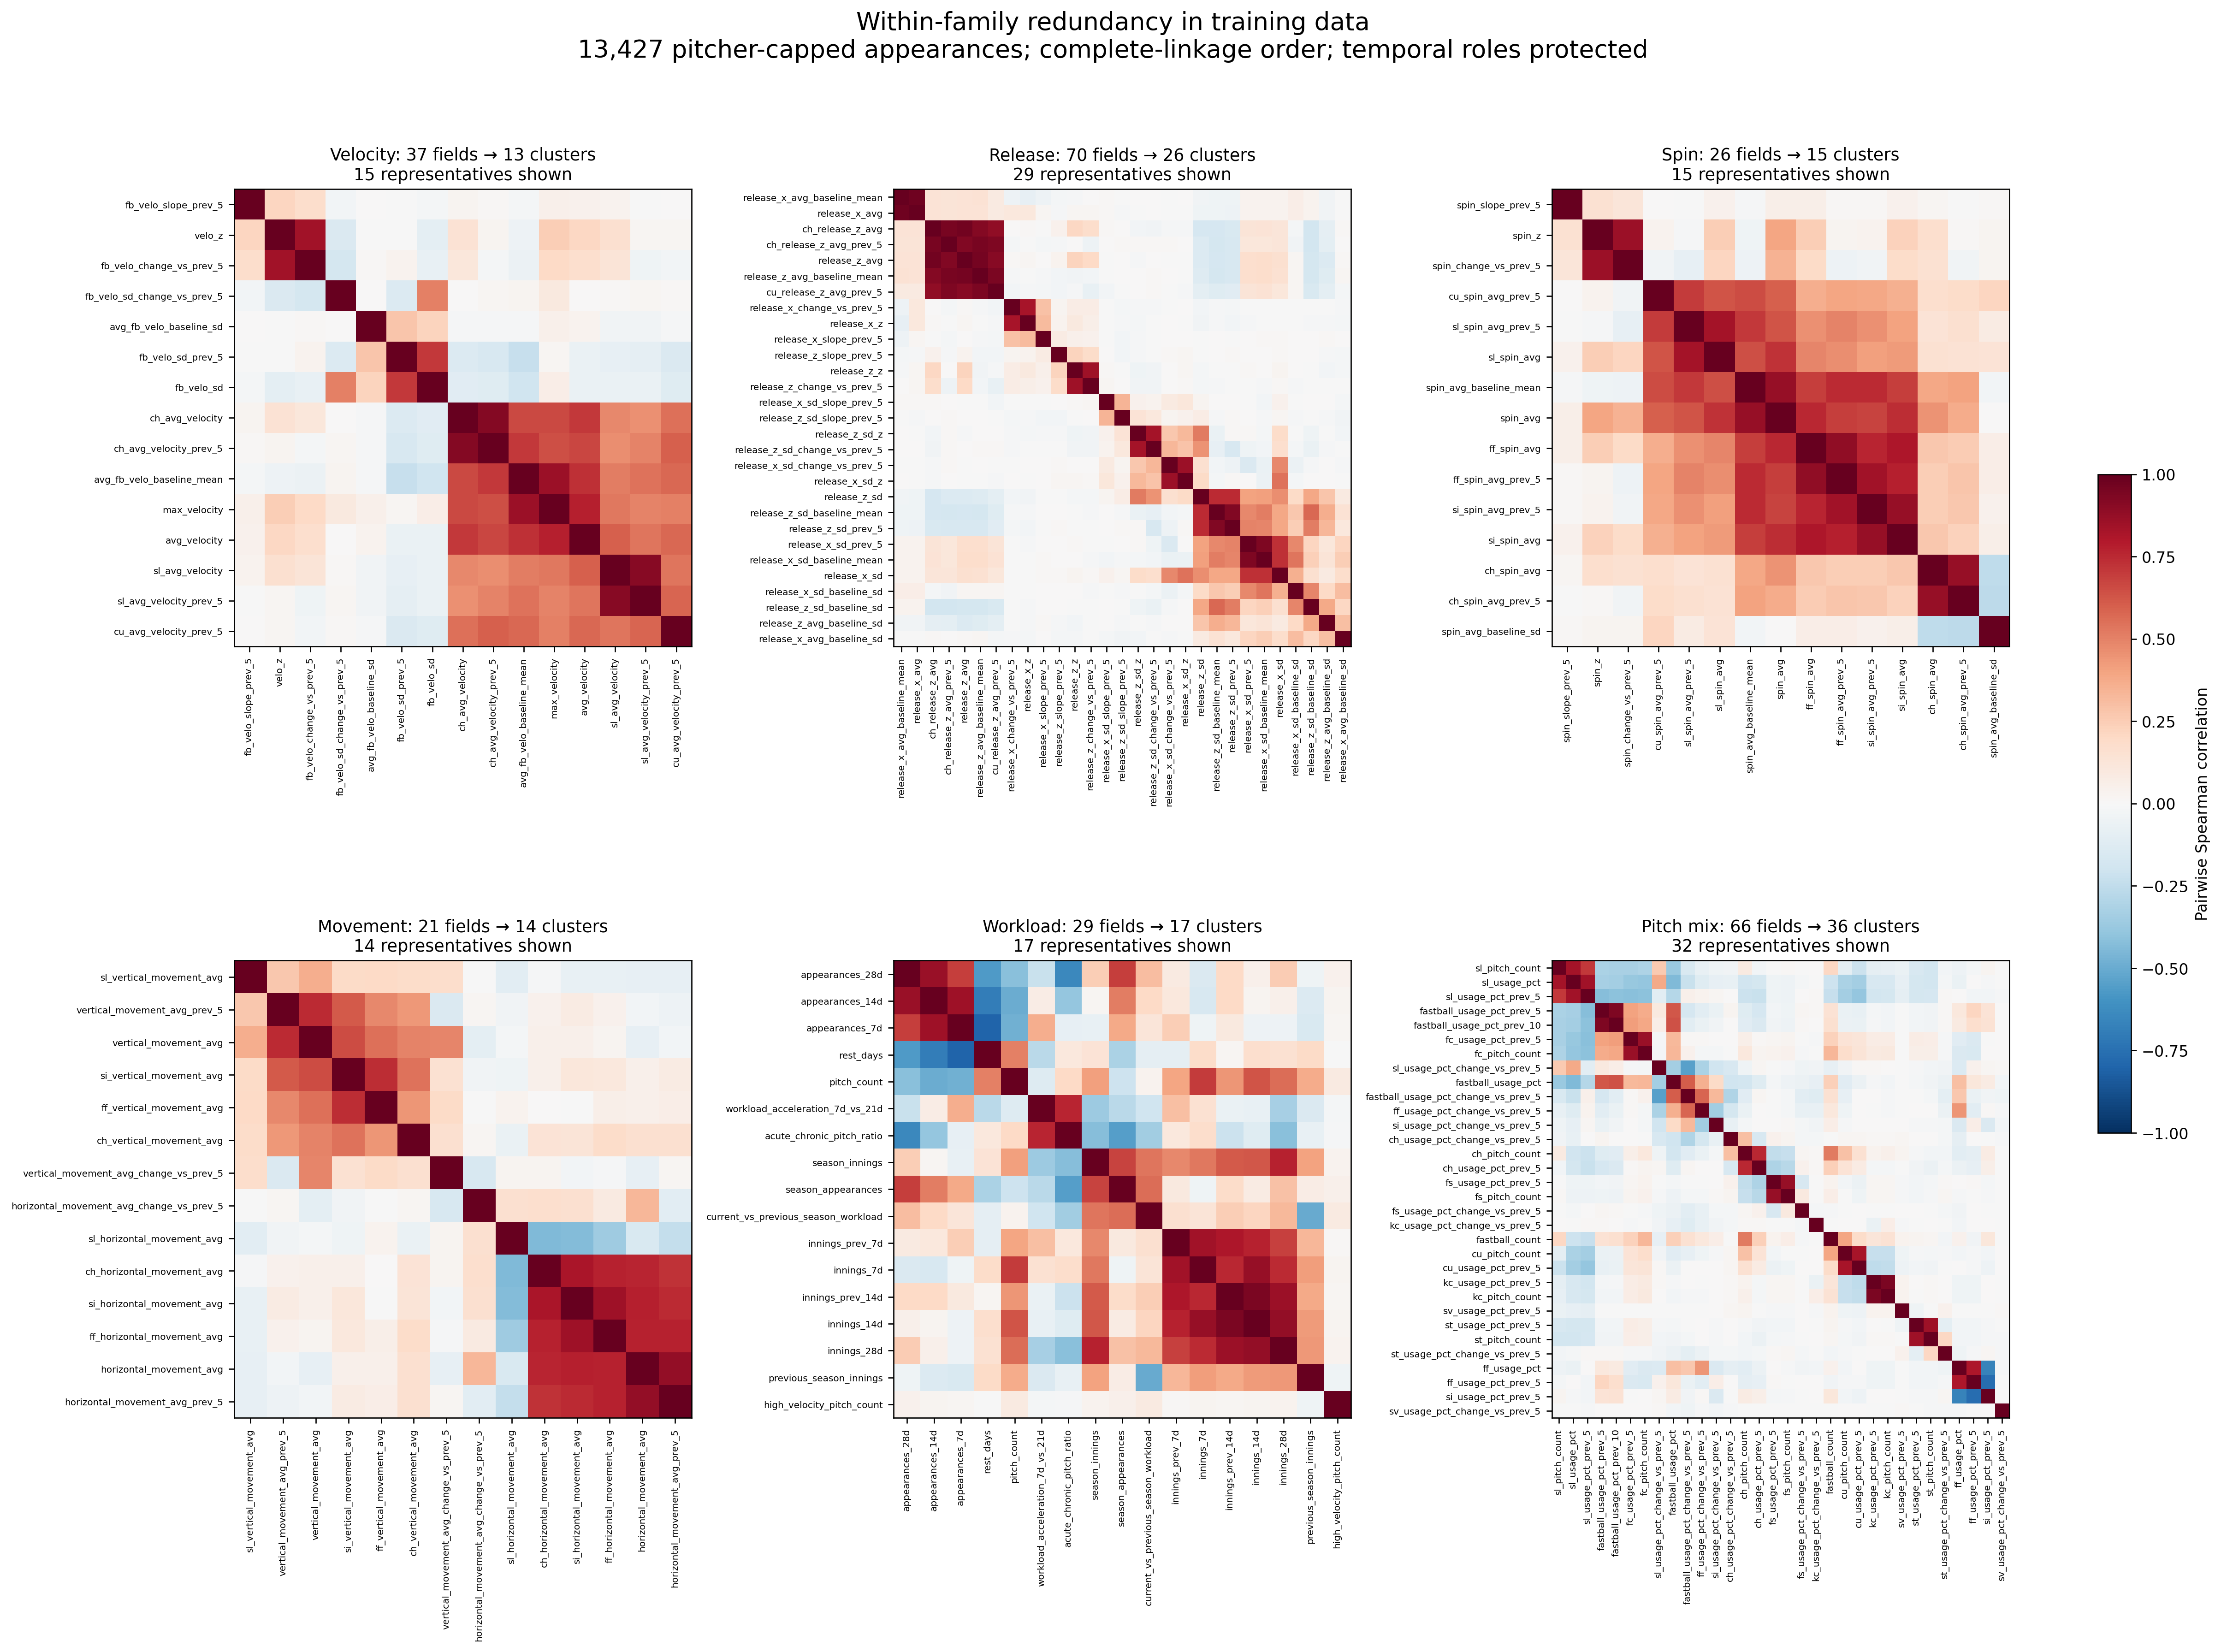

,feature_group,correlation_cluster,features,representatives,members
0,Appearance performance,Appearance performance__001,3,1,hbp_count;hbp_rate;hit_batters
1,Appearance performance,Appearance performance__002,4,1,statcast_batters_faced;outs_recorded;innings_p...
2,Appearance performance,Appearance performance__003,1,1,strikeouts
3,Appearance performance,Appearance performance__004,1,1,walk_rate
4,Appearance performance,Appearance performance__005,1,1,walks
...,...,...,...,...,...
184,Workload and rest,Workload and rest__013,2,1,pitches_prev_14d;innings_prev_14d
185,Workload and rest,Workload and rest__014,2,1,pitches_14d;innings_14d
186,Workload and rest,Workload and rest__015,4,1,pitches_prev_28d;pitches_28d;innings_prev_28d;...
187,Workload and rest,Workload and rest__016,1,1,previous_season_innings


,feature_a,feature_b,group_a,group_b,pearson,spearman,coobserved_rows,same_group,high_correlation
0,hbp_count,hit_batters,Appearance performance,Appearance performance,1.000000,1.000000,13427,True,True
1,appearances_prev_7d,appearances_7d,Workload and rest,Workload and rest,1.000000,1.000000,13249,True,True
2,outs_recorded,innings_pitched,Appearance performance,Appearance performance,1.000000,1.000000,13427,True,True
3,appearances_prev_28d,appearances_28d,Workload and rest,Workload and rest,1.000000,1.000000,13119,True,True
4,release_x_sd_baseline_count,release_z_sd_baseline_count,Measurement coverage and history support,Measurement coverage and history support,1.000000,1.000000,13427,True,True
5,release_z_avg_baseline_count,zone_pct_baseline_count,Measurement coverage and history support,Measurement coverage and history support,1.000000,1.000000,13427,True,True
6,total_pitches,pitch_count,Workload and rest,Workload and rest,1.000000,1.000000,13427,True,True
7,observed_prior_mlb_appearances,workload_history_appearances,Pitcher background and experience,Measurement coverage and history support,1.000000,1.000000,13427,False,True
8,appearances_prev_14d,appearances_14d,Workload and rest,Workload and rest,1.000000,1.000000,13200,True,True
9,release_x_avg_baseline_count,zone_pct_baseline_count,Measurement coverage and history support,Measurement coverage and history support,1.000000,1.000000,13427,True,True


In [3]:
plot('01_within_family_redundancy')
display(read_table('cluster_summary'))
display(read_table('high_correlation_pairs').head(30))

## Cross-family redundancy

Fractions and pair counts reveal hidden overlap, including role/workload, movement/release and historical support. The canonical summary combines unordered family pairs; it corrects display grouping without recomputing correlations. A high correlation can reflect a deterministic identity, role, pitch selection or shared measurements. It does not establish interchangeable injury information.

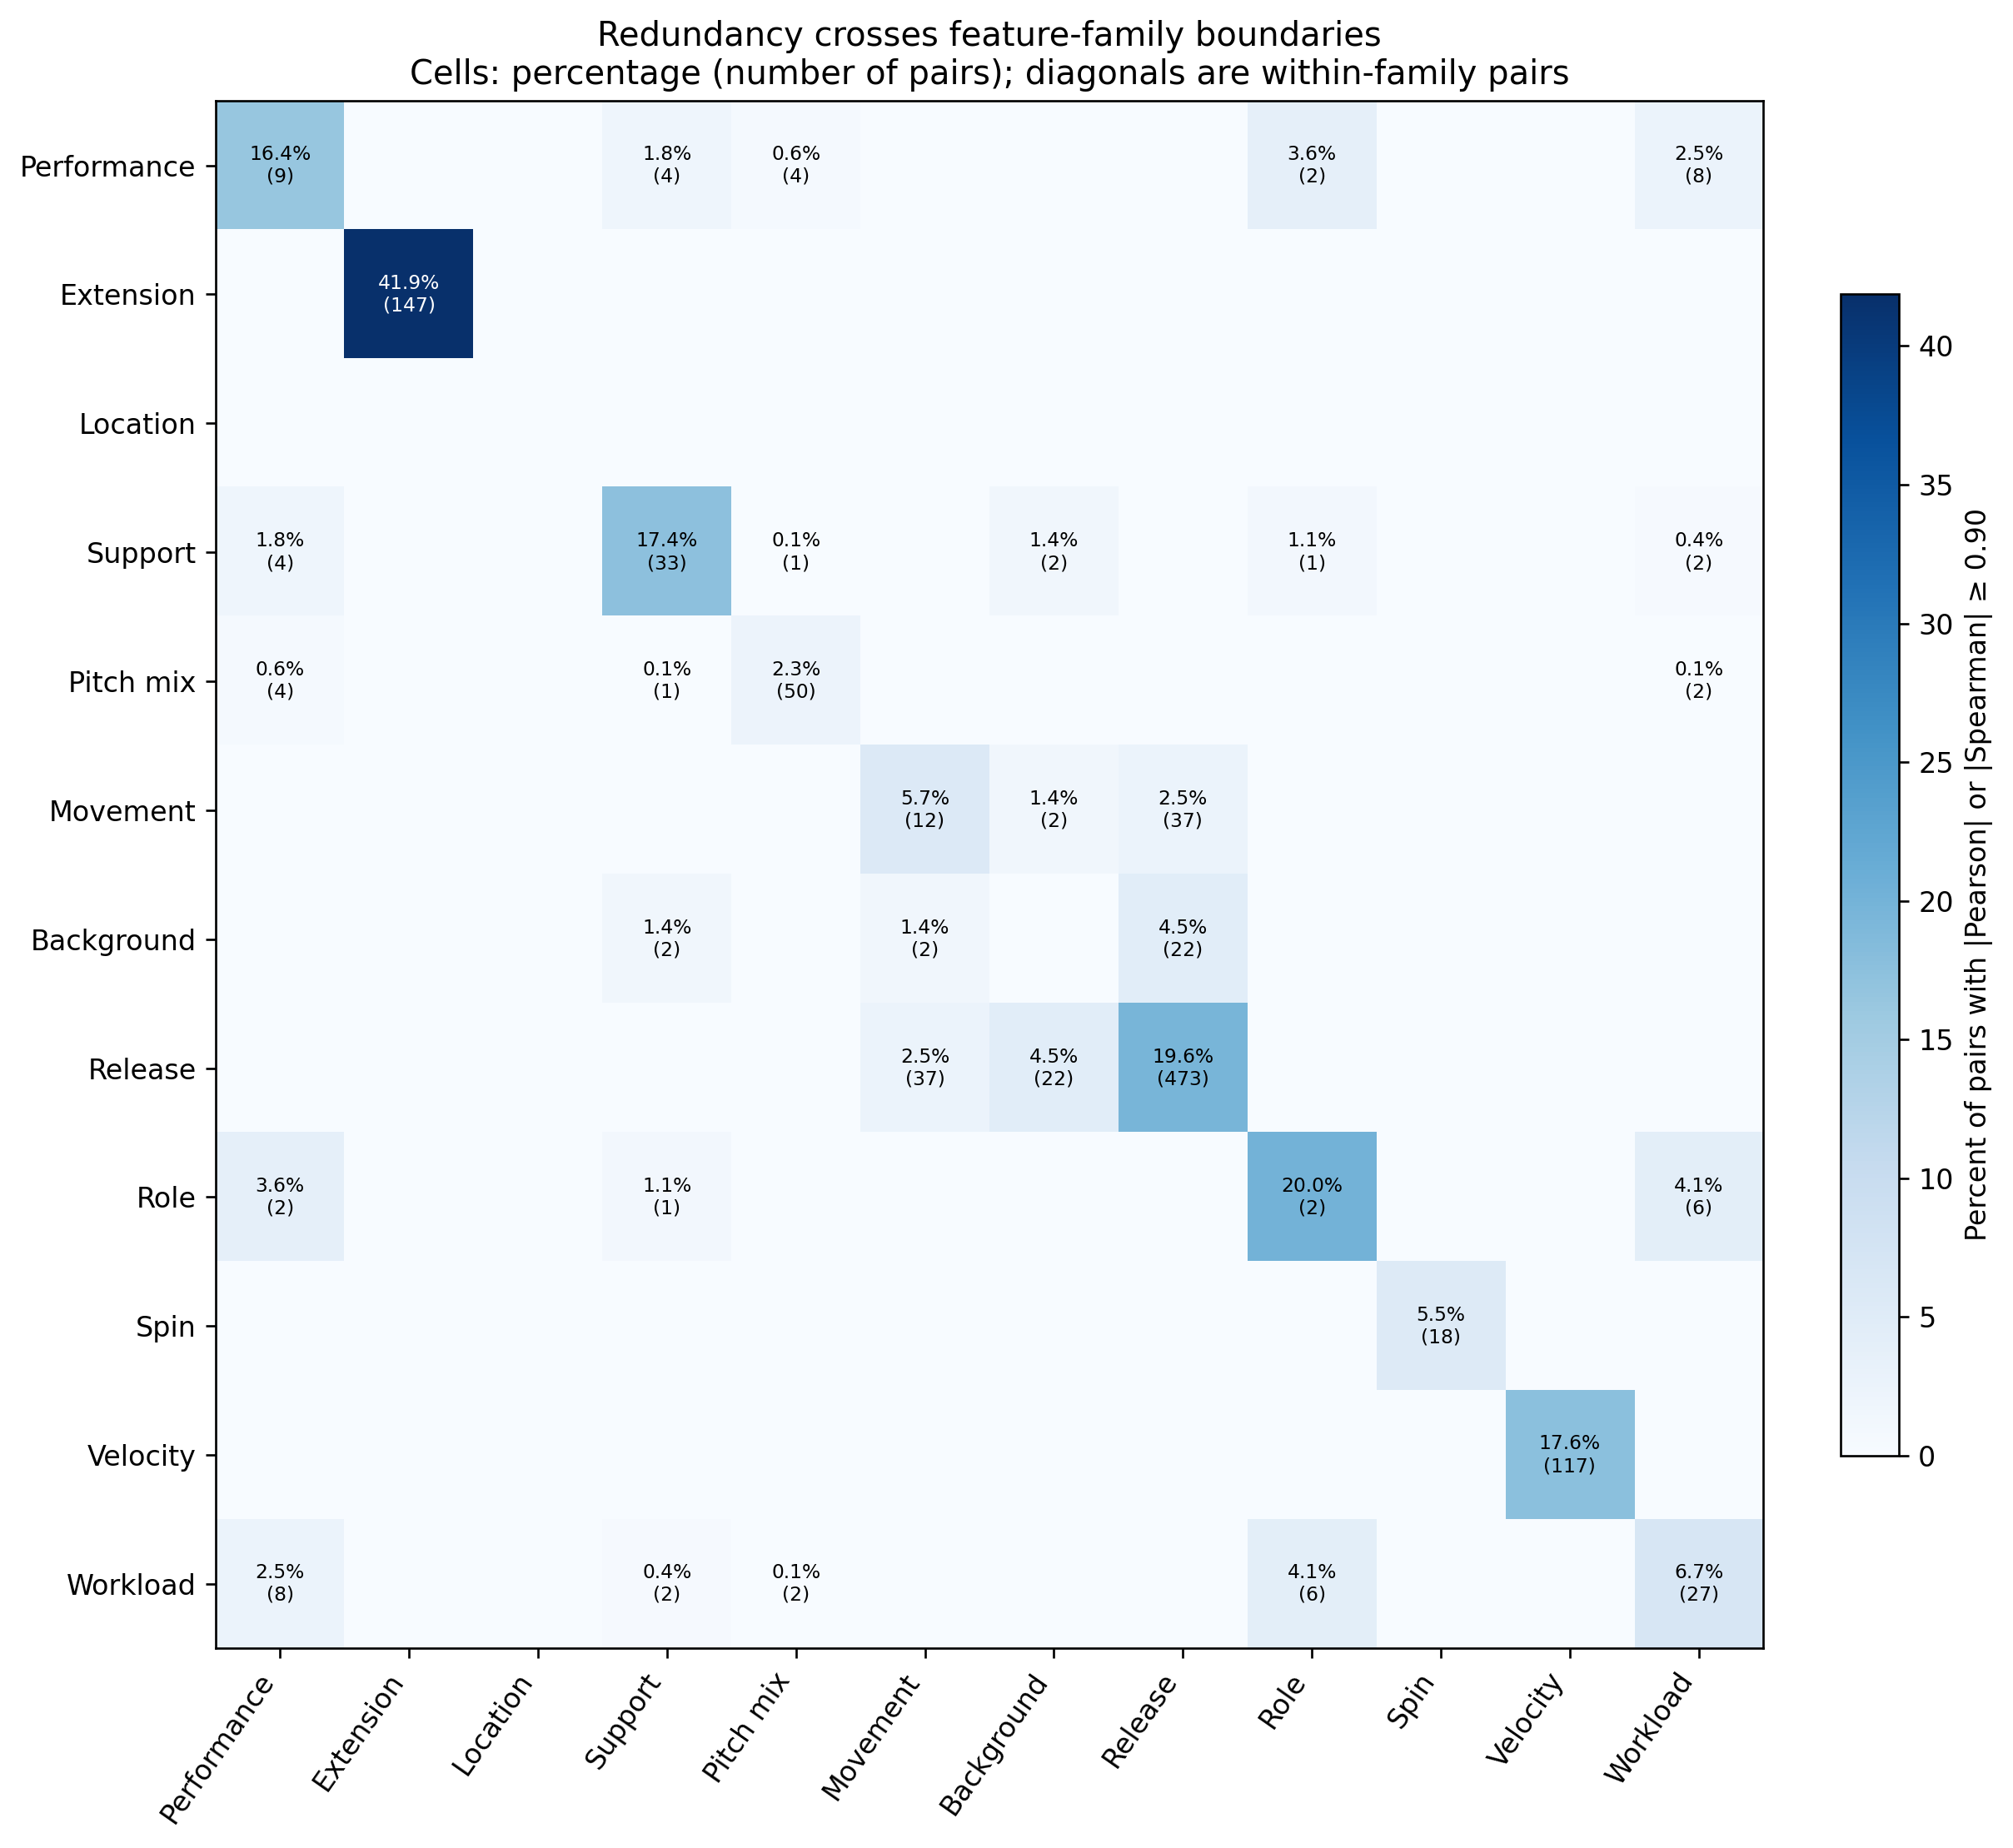

,feature_a,feature_b,group_a,group_b,pearson,spearman,coobserved_rows,same_group,high_correlation
87,observed_prior_mlb_appearances,workload_history_appearances,Pitcher background and experience,Measurement coverage and history support,1.000000,1.000000,13427,False,True
88,observed_prior_mlb_appearances,prior_appearance_count,Pitcher background and experience,Measurement coverage and history support,1.000000,0.999999,13427,False,True
1,total_pitches,velocity_measured_count,Workload and rest,Measurement coverage and history support,0.999966,0.999946,13427,False,True
18,velocity_measured_count,pitch_count,Measurement coverage and history support,Workload and rest,0.999966,0.999946,13427,False,True
10,statcast_batters_faced,pitch_count,Appearance performance,Workload and rest,0.982602,0.957313,13427,False,True
0,total_pitches,statcast_batters_faced,Workload and rest,Appearance performance,0.982602,0.957313,13427,False,True
7,statcast_batters_faced,velocity_measured_count,Appearance performance,Measurement coverage and history support,0.982572,0.957217,13427,False,True
6,total_pitches,batters_faced,Workload and rest,Appearance performance,0.982375,0.956421,13427,False,True
69,pitch_count,batters_faced,Workload and rest,Appearance performance,0.982375,0.956421,13427,False,True
19,velocity_measured_count,batters_faced,Measurement coverage and history support,Appearance performance,0.982343,0.956319,13427,False,True


,partition,season,feature,missing_fraction,rows
9,test,2024,extension_avg,0.001669,13781
11,test,2024,arm_angle_avg,0.005805,13781
13,test,2024,spin_avg,0.004354,13781
38,test,2024,velo_drop_game,0.821856,13781
547,test,2025,extension_avg,0.000000,13884
549,test,2025,arm_angle_avg,0.000432,13884
551,test,2025,spin_avg,0.002305,13884
576,test,2025,velo_drop_game,0.815975,13884
1085,train,2015,extension_avg,0.006310,11252
1087,train,2015,arm_angle_avg,1.000000,11252


In [4]:
plot('02_cross_family_redundancy')
display(read_table('cross_group_high_pairs').sort_values('spearman',key=lambda x:x.abs(),ascending=False).head(25))
display(read_table('feature_availability_by_season').query("feature in ['arm_angle_avg','spin_avg','velo_drop_game','extension_avg']"))

**Interpretation:** Read redundancy alongside timing. A current level, strictly historical level and current departure can correlate strongly while answering different prediction questions. The next notebook tests conditional predictive value rather than assuming the correlation representatives are sufficient.